# Campos de un dipolo eléctrico oscilante

En este notebook estudio los campos de un dipolo eléctrico que oscila en la
dirección $z$. Me interesa ver qué cambia al alejarse del dipolo y cómo se
transporta la energía en cada región.

Voy a comparar tres distancias medidas en longitudes de onda. Primero separo
los términos de los campos según su dependencia con la distancia. Después
los sumo para ver la dirección de los campos y del flujo de energía en un
instante dado.

In [1]:
%pip install numpy "matplotlib>=3.7" ipywidgets

Note: you may need to restart the kernel to use updated packages.


In [17]:
from pathlib import Path

CARPETA_FIGURAS = Path("figuras")
CARPETA_FIGURAS.mkdir(exist_ok=True)

def guardar_figura(fig, nombre):
    ruta = CARPETA_FIGURAS / nombre
    fig.savefig(ruta, dpi=300, bbox_inches="tight", facecolor="white")
    print(f"Imagen guardada en {ruta.resolve()}")

## 1. Campos del dipolo

El momento dipolar es

$$
\mathbf p(t)=p_0\cos(\omega t)\,\hat{\mathbf z}.
$$

El ángulo $\theta$ se mide desde el eje $+z$. En un punto a distancia $r$,
el campo depende del momento del dipolo en el tiempo retardado
$t_r=t-r/c$. Si $\psi=\omega(t-r/c)$, entonces

$$
p_r=p_0\cos\psi,\qquad
\dot p_r=-\omega p_0\sin\psi,\qquad
\ddot p_r=-\omega^2p_0\cos\psi.
$$

Al especializar los resultados del problema 10.34 de Griffiths a un dipolo
orientado en $z$, quedan tres componentes distintas de cero:

$$
\begin{aligned}
E_r &=
\frac{2\cos\theta}{4\pi\epsilon_0}
\left(\frac{p_r}{r^3}+\frac{\dot p_r}{cr^2}\right),\\
E_\theta &=
\frac{\sin\theta}{4\pi\epsilon_0}
\left(\frac{p_r}{r^3}+\frac{\dot p_r}{cr^2}
+\frac{\ddot p_r}{c^2r}\right),\\
B_\phi &=
\frac{\mu_0\sin\theta}{4\pi}
\left(\frac{\dot p_r}{r^2}+\frac{\ddot p_r}{cr}\right).
\end{aligned}
$$

El código evalúa estas expresiones para el dipolo ideal. La fuente se
considera puntual, así que el origen queda fuera de las gráficas. Para
aplicar el modelo a una fuente real, su tamaño debe ser pequeño frente
a la distancia de observación y a $c/\omega$, y la contribución del
dipolo eléctrico debe dominar.

In [14]:
%matplotlib inline

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize

C = 299_792_458.0
MU0 = 4 * np.pi * 1e-7
EPS0 = 1 / (MU0 * C**2)
KE = 1 / (4 * np.pi * EPS0)

F = 100e6                
P0 = 1e-9                 
LAMBDA = C / F
FASE = 0.125              

REGIMENES = (
    ("Región cercana", 0.03),
    ("Transición", 1 / (2 * np.pi)),
    ("Región de radiación", 5.0),
)

AZUL = "#115a91"
NARANJA = "#ad5b17"
VERDE = "#15745f"

plt.rcParams.update({
    "figure.dpi": 110,
    "font.size": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

def campos_esfericos(r, theta, t, p0=P0, f=F):
    r, theta, t = np.broadcast_arrays(
        np.asarray(r, dtype=float),
        np.asarray(theta, dtype=float),
        np.asarray(t, dtype=float),
    )

    if np.any(~np.isfinite(r)) or np.any(r <= 0):
        raise ValueError("La distancia r debe ser finita y positiva.")
    if not np.isfinite(f) or f <= 0 or not np.isfinite(p0) or p0 <= 0:
        raise ValueError("La frecuencia y la amplitud deben ser positivas.")

    omega = 2 * np.pi * f
    psi = omega * (t - r / C)
    p = p0 * np.cos(psi)
    dp = -omega * p0 * np.sin(psi)
    ddp = -omega**2 * p0 * np.cos(psi)
    termino_3 = p / r**3
    termino_2 = dp / (C * r**2)
    termino_1 = ddp / (C**2 * r)
    er = 2 * KE * np.cos(theta) * (termino_3 + termino_2)
    etheta = KE * np.sin(theta) * (termino_3 + termino_2 + termino_1)
    bphi = KE / C * np.sin(theta) * (termino_2 + termino_1)
    return er, etheta, bphi


def poynting_instantaneo(r, theta, t, p0=P0, f=F):
    er, etheta, bphi = campos_esfericos(r, theta, t, p0, f)
    sr = etheta * bphi / MU0
    stheta = -er * bphi / MU0
    return sr, stheta


def potencia_por_angulo_solido(theta, p0=P0, f=F):
    omega = 2 * np.pi * f
    factor = MU0 * p0**2 * omega**4 / (32 * np.pi**2 * C)
    return factor * np.sin(theta)**2


def poynting_promedio(r, theta, p0=P0, f=F):
    r = np.asarray(r, dtype=float)
    if np.any(~np.isfinite(r)) or np.any(r <= 0):
        raise ValueError("La distancia r debe ser finita y positiva.")

    sr = potencia_por_angulo_solido(theta, p0, f) / r**2
    return sr, np.zeros_like(sr)

## 2. Qué espero al alejarme del dipolo

Los términos tienen distintas potencias de $r$ en el denominador.
Por eso espero que el de $1/r^3$ domine en el campo eléctrico cerca
del dipolo y que el de $1/r$ domine lejos. En el campo magnético, los
órdenes que compiten son $1/r^2$ y $1/r$.

Elegí estas distancias:

- $r=0.03\lambda$. Espero que $E$ todavía tenga una componente radial importante.
- $r=\lambda/(2\pi)$. Aquí $kr=1$ y espero que varios términos sean comparables.
- $r=5\lambda$. Espero que $E$ sea casi transversal y que la energía viaje
  principalmente hacia afuera.

La gráfica compara la amplitud de cada término a $60^\circ$ del eje.
Como son amplitudes separadas, permiten ver cuál domina. Para obtener
el campo en un instante hay que sumar los términos con sus signos.

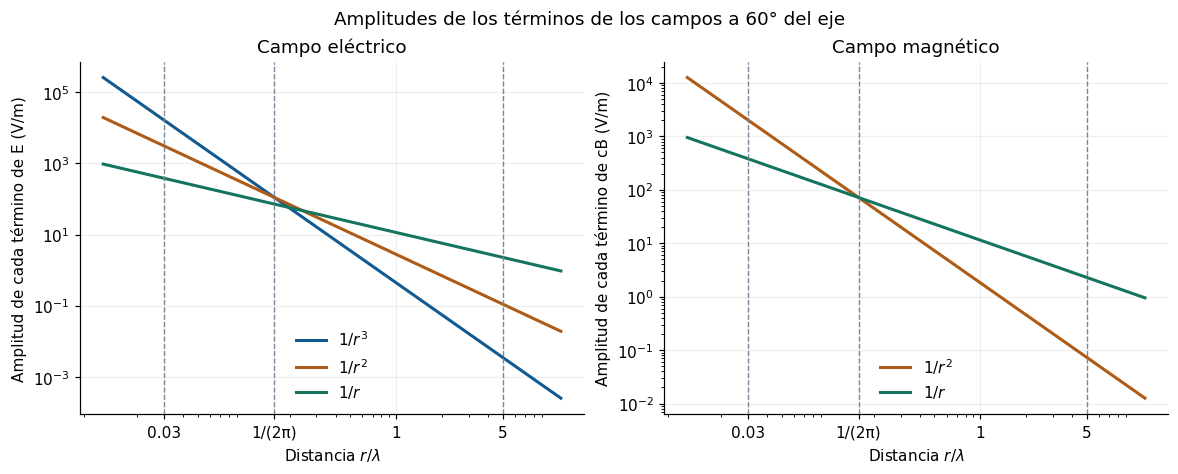

Imagen guardada en C:\Users\gusta\figuras\01_amplitudes.png


In [18]:
theta = np.deg2rad(60)
omega = 2 * np.pi * F
q = np.geomspace(0.012, 12, 700)
r = q * LAMBDA

factor_dipolar = np.hypot(2 * np.cos(theta), np.sin(theta))
factor_transversal = abs(np.sin(theta))

e3 = KE * P0 * factor_dipolar / r**3
e2 = KE * omega * P0 * factor_dipolar / (C * r**2)
e1 = KE * omega**2 * P0 * factor_transversal / (C**2 * r)

cb2 = KE * omega * P0 * factor_transversal / (C * r**2)
cb1 = KE * omega**2 * P0 * factor_transversal / (C**2 * r)

fig, axes = plt.subplots(1, 2, figsize=(10.6, 4.2), layout="constrained")

axes[0].loglog(q, e3, color=AZUL, lw=2, label=r"$1/r^3$")
axes[0].loglog(q, e2, color=NARANJA, lw=2, label=r"$1/r^2$")
axes[0].loglog(q, e1, color=VERDE, lw=2, label=r"$1/r$")
axes[0].set(title="Campo eléctrico", ylabel="Amplitud de cada término de E (V/m)")

axes[1].loglog(q, cb2, color=NARANJA, lw=2, label=r"$1/r^2$")
axes[1].loglog(q, cb1, color=VERDE, lw=2, label=r"$1/r$")
axes[1].set(title="Campo magnético", ylabel="Amplitud de cada término de cB (V/m)")

for ax in axes:
    for _, distancia in REGIMENES:
        ax.axvline(distancia, color="#76879a", ls="--", lw=0.9)

    ax.set_xlabel(r"Distancia $r/\lambda$")
    ax.set_xticks(
        [0.03, 1 / (2 * np.pi), 1, 5],
        labels=["0.03", "1/(2π)", "1", "5"],
    )
    ax.grid(alpha=0.2)
    ax.legend(frameon=False)

fig.suptitle("Amplitudes de los términos de los campos a 60° del eje")
plt.show()

guardar_figura(fig, "01_amplitudes.png")
plt.show()


### Campos totales al variar la distancia

Fijo el ángulo en 60° y el tiempo en t/T = 0.125. Luego calculo las
magnitudes de E y B a distintas distancias sobre ese mismo rayo.
Las líneas punteadas marcan las tres distancias que elegí para
comparar la región cercana, la transición y la región de radiación.

Aunque el tiempo de observación es el mismo en toda la gráfica,
el tiempo retardado cambia con la distancia. Por eso, al alejarse
del dipolo, las curvas presentan máximos y mínimos. En la región
lejana, los máximos van disminuyendo conforme domina el término
de radiación, que cae como 1/r.

Imagen guardada en C:\Users\gusta\figuras\02_campos_totales.png


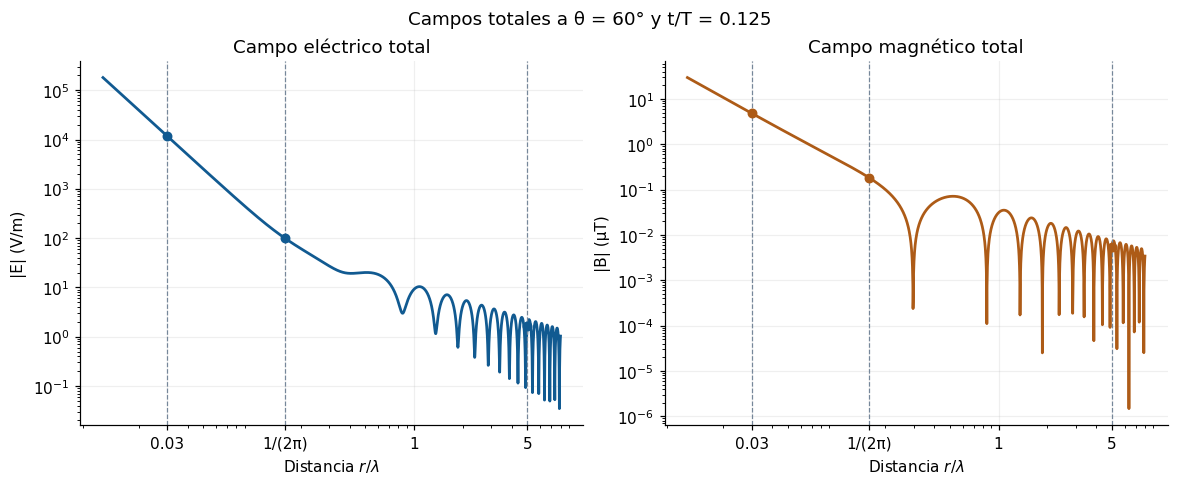

Región                        r/λ      |E| (V/m)       |B| (µT)
Región cercana              0.030        11582.1        4.82994
Transición                  0.159        99.6384       0.182634
Región de radiación         5.000        1.66351     0.00555102


In [19]:
theta_perfil = np.deg2rad(60)
tiempo_perfil = FASE / F
q_perfil = np.geomspace(0.012, 8.0, 2400)
r_perfil = q_perfil * LAMBDA
er, etheta, bphi = campos_esfericos(
    r_perfil, theta_perfil, tiempo_perfil,
)
magnitud_e = np.hypot(er, etheta)
magnitud_b = np.abs(bphi)

q_marcas = np.array([q for _, q in REGIMENES])
er_m, etheta_m, bphi_m = campos_esfericos(
    q_marcas * LAMBDA, theta_perfil, tiempo_perfil,
)
e_marcas = np.hypot(er_m, etheta_m)
b_marcas = np.abs(bphi_m)

fig, axes = plt.subplots(
    1, 2, figsize=(10.6, 4.3), sharex=True, layout="constrained",
)

axes[0].loglog(q_perfil, magnitud_e, color=AZUL, lw=1.8)
axes[0].scatter(q_marcas, e_marcas, color=AZUL, s=30, zorder=3)
axes[0].set(title="Campo eléctrico total", ylabel="|E| (V/m)")

axes[1].loglog(q_perfil, 1e6 * magnitud_b, color=NARANJA, lw=1.8)
axes[1].scatter(q_marcas, 1e6 * b_marcas, color=NARANJA, s=30, zorder=3)
axes[1].set(title="Campo magnético total", ylabel="|B| (µT)")

for ax in axes:
    for q in q_marcas:
        ax.axvline(q, color="#76879a", ls="--", lw=0.8)

    ax.set_xlabel(r"Distancia $r/\lambda$")
    ax.set_xticks(
        [q_marcas[0], q_marcas[1], 1, q_marcas[2]],
        labels=["0.03", "1/(2π)", "1", "5"],
    )
    ax.grid(alpha=0.2)

fig.suptitle(f"Campos totales a θ = 60° y t/T = {FASE:g}")
guardar_figura(fig, "02_campos_totales.png")
plt.show()

print(f"{'Región':24} {'r/λ':>8} {'|E| (V/m)':>14} {'|B| (µT)':>14}")
for (nombre, q), e, b in zip(REGIMENES, e_marcas, b_marcas):
    print(f"{nombre:24} {q:8.3f} {e:14.6g} {1e6 * b:14.6g}")

## 3. Hacia dónde va la energía

Como el campo magnético solo tiene componente azimutal, el producto
$\mathbf E\times\mathbf B$ tiene una parte radial y otra angular:

$$
S_r=\frac{E_\theta B_\phi}{\mu_0},
\qquad
S_\theta=-\frac{E_r B_\phi}{\mu_0}.
$$

Para sacar el promedio en un período, defino
$a=p_0/r^3$, $b=\omega p_0/(cr^2)$ y $d=\omega^2p_0/(c^2r)$.
De las expresiones de los campos se obtiene

$$
\begin{aligned}
E_r &= 2k_e\cos\theta(a\cos\psi-b\sin\psi),\\
E_\theta &= k_e\sin\theta[(a-d)\cos\psi-b\sin\psi],\\
B_\phi &= \frac{k_e}{c}\sin\theta(-d\cos\psi-b\sin\psi),
\end{aligned}
$$

donde $k_e=1/(4\pi\epsilon_0)$. Los cuadrados del seno y del coseno
promedian $1/2$, y el producto seno por coseno promedia cero.
Además, $b^2=ad$. Así, al promediar el producto de $E_\theta$ con
$B_\phi$ queda el factor $(d^2-ad+b^2)/2=d^2/2$. Para el producto
de $E_r$ con $B_\phi$ queda $(-ad+b^2)/2=0$. Entonces

$$
\langle\mathbf S\rangle=
\frac{\mu_0 p_0^2\omega^4}{32\pi^2 c r^2}
\sin^2\theta\,\hat{\mathbf r}.
$$

Voy a comparar el flujo instantáneo con ese promedio en cortes del
plano $xz$. En la fila de arriba, las flechas muestran la dirección
de $E$ y el color indica $B_y$, que apunta perpendicular al plano.
En la fila de abajo, las flechas muestran el flujo y el color indica
su componente radial. Rojo significa hacia afuera y azul hacia el
dipolo.

Cada anillo tiene su propia escala de color. Las flechas muestran
direcciones y tienen longitud fija. Las magnitudes se comparan en
la gráfica anterior y en la tabla de la sección siguiente.

Imagen guardada en C:\Users\gusta\figuras\03_cortes_instantaneos.png


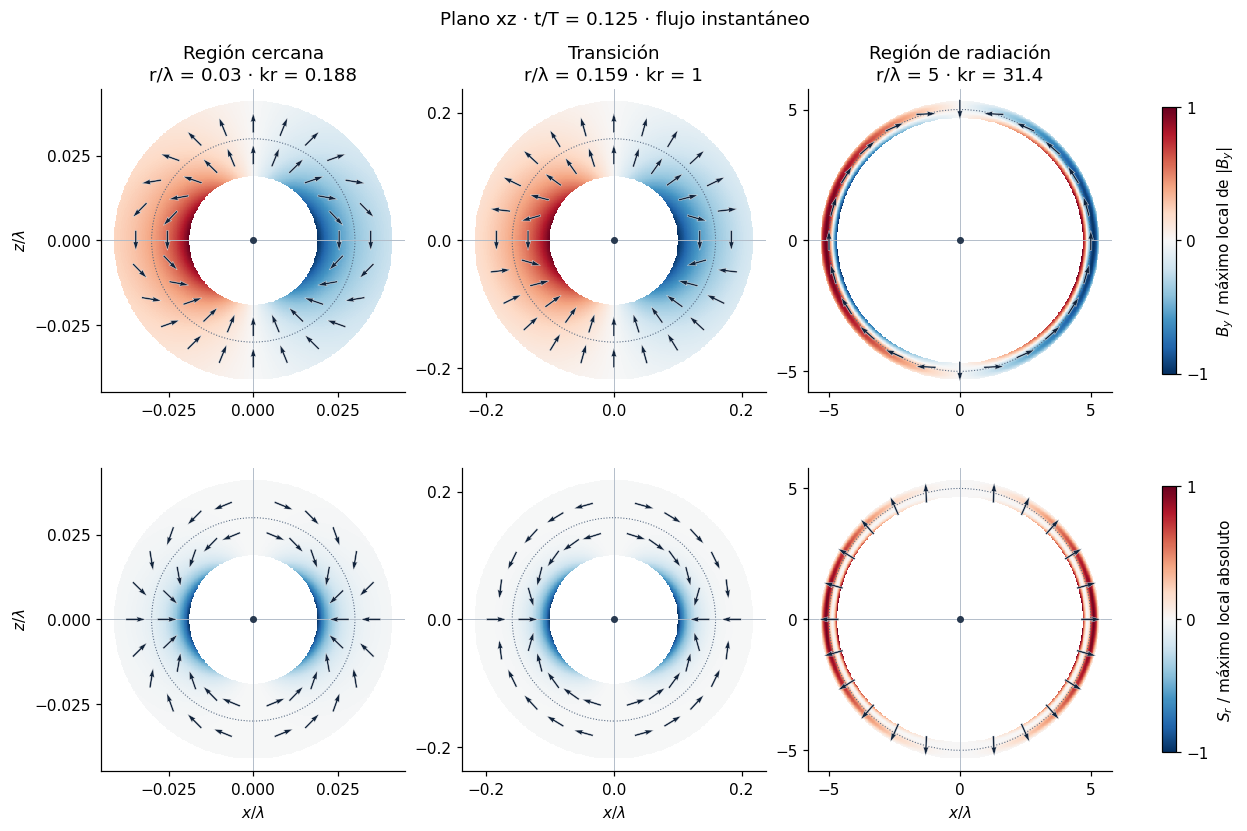

Imagen guardada en C:\Users\gusta\figuras\04_cortes_promedio.png


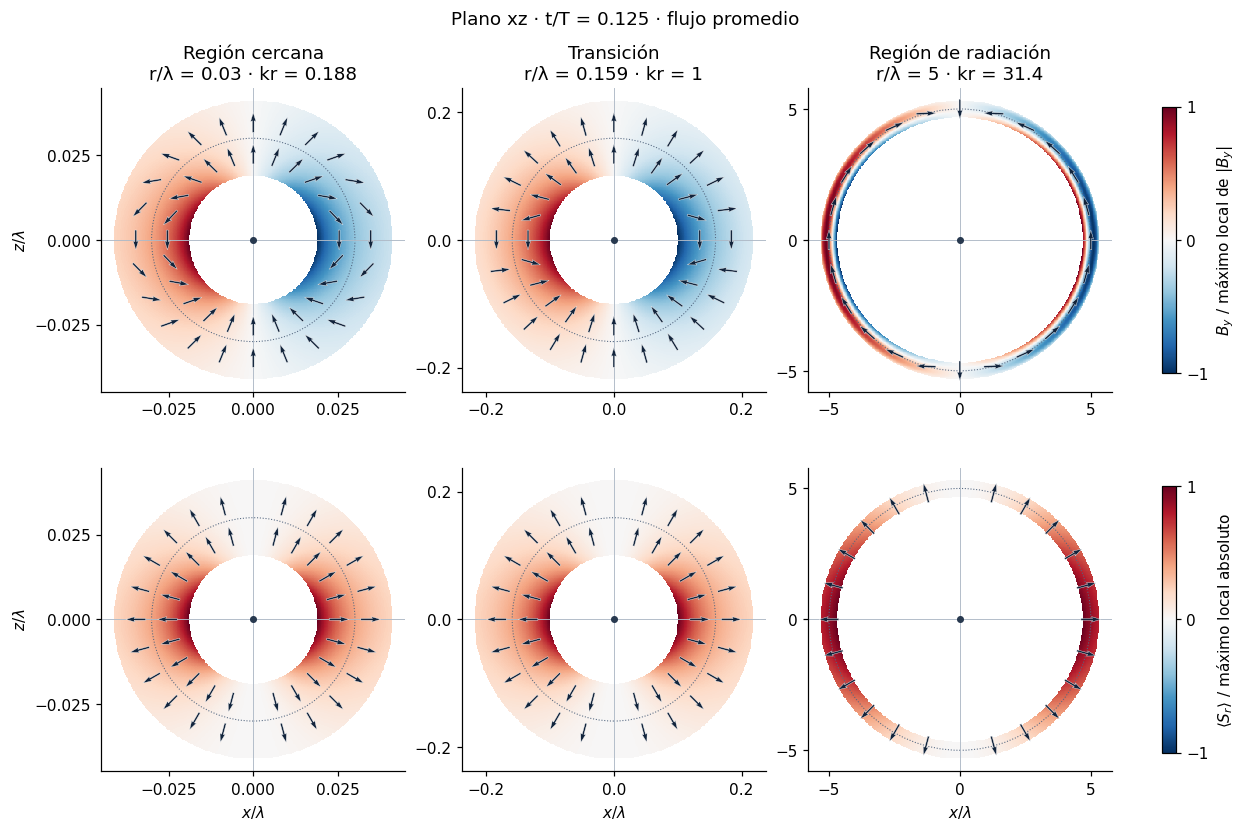

In [20]:
def componentes_corte(x, z, fase, promedio=False):
    q = np.hypot(x, z)
    theta = np.arctan2(np.abs(x), z)
    r = q * LAMBDA
    nr_x, nr_z = x / q, z / q
    nt_x = np.sign(x) * z / q
    nt_z = -np.abs(x) / q

    er, etheta, bphi = campos_esfericos(r, theta, fase / F)

    if promedio:
        sr, stheta = poynting_promedio(r, theta)
    else:
        sr = etheta * bphi / MU0
        stheta = -er * bphi / MU0

    ex = er * nr_x + etheta * nt_x
    ez = er * nr_z + etheta * nt_z
    by = np.sign(x) * bphi

    sx = sr * nr_x + stheta * nt_x
    sz = sr * nr_z + stheta * nt_z

    return ex, ez, by, sx, sz, sr


def dibujar_flechas(ax, x, z, vx, vz, longitud):
    magnitud = np.hypot(vx, vz)
    usar = magnitud > 1e-7 * np.max(magnitud)

    if np.any(usar):
        ax.quiver(
            x[usar], z[usar],
            longitud * vx[usar] / magnitud[usar],
            longitud * vz[usar] / magnitud[usar],
            angles="xy", scale_units="xy", scale=1,
            pivot="mid", color="#12243c", edgecolor="white",
            linewidth=0.25, width=0.006, zorder=4,
        )


def figura_cortes(regimenes=REGIMENES, fase=FASE, promedio=False):
    cantidad = len(regimenes)
    fig, axes = plt.subplots(
        2, cantidad, squeeze=False,
        figsize=(3.45 * cantidad + 0.9, 7.5),
        layout="constrained",
    )

    modo = "promedio" if promedio else "instantáneo"
    fig.suptitle(f"Plano xz · t/T = {fase:.3f} · flujo {modo}")

    for col, (nombre, centro) in enumerate(regimenes):
        ancho = min(0.37 * centro, 0.32)
        interior = centro - ancho
        exterior = centro + ancho
        limite = 1.09 * exterior

        eje = np.linspace(-limite, limite, 391)
        x, z = np.meshgrid(eje, eje)
        q = np.hypot(x, z)
        mascara = (q >= interior) & (q <= exterior)

        _, _, by, _, _, sr = componentes_corte(
            x[mascara], z[mascara], fase, promedio,
        )

        ax_b, ax_s = axes[:, col]
        mapas = []

        for ax, datos in ((ax_b, by), (ax_s, sr)):
            fondo = np.full_like(x, np.nan)
            maximo = max(np.max(np.abs(datos)), np.finfo(float).tiny)
            fondo[mascara] = datos / maximo

            mapa = ax.pcolormesh(
                x, z, fondo, shading="auto",
                cmap="RdBu_r", norm=Normalize(-1, 1),
            )
            mapas.append(mapa)

            ax.axhline(0, color="#afbac7", lw=0.6)
            ax.axvline(0, color="#afbac7", lw=0.6)
            ax.add_patch(plt.Circle(
                (0, 0), centro, fill=False, ls=":",
                color="#546780", lw=0.7,
            ))
            ax.scatter(0, 0, s=13, color="#28394f", zorder=5)
            ax.set(
                xlim=(-limite, limite),
                ylim=(-limite, limite),
                aspect="equal",
            )
            ax.locator_params(axis="both", nbins=4)

            if col == 0:
                ax.set_ylabel(r"$z/\lambda$")

        ax_b.set_title(
            f"{nombre}\nr/λ = {centro:.3g} · kr = {2 * np.pi * centro:.3g}"
        )
        ax_s.set_xlabel(r"$x/\lambda$")

        angulos = np.linspace(0, 2 * np.pi, 24, endpoint=False)
        radios = [centro] if ancho / centro < 0.15 else (
            centro + np.array([-0.42, 0.42]) * ancho
        )
        radios, angulos = np.meshgrid(radios, angulos)
        xq = radios * np.sin(angulos)
        zq = radios * np.cos(angulos)

        ex, ez, _, sx, sz, _ = componentes_corte(xq, zq, fase, promedio)
        dibujar_flechas(ax_b, xq, zq, ex, ez, 0.13 * limite)
        dibujar_flechas(ax_s, xq, zq, sx, sz, 0.13 * limite)

    fig.colorbar(
        mapas[0], ax=axes[0, :], shrink=0.72, ticks=[-1, 0, 1],
        label=r"$B_y$ / máximo local de $|B_y|$",
    )

    etiqueta = r"$\langle S_r\rangle$" if promedio else r"$S_r$"
    fig.colorbar(
        mapas[1], ax=axes[1, :], shrink=0.72, ticks=[-1, 0, 1],
        label=etiqueta + " / máximo local absoluto",
    )

    return fig


fig_instantanea = figura_cortes()
guardar_figura(fig_instantanea, "03_cortes_instantaneos.png")
plt.show()

fig_promedio = figura_cortes(promedio=True)
guardar_figura(fig_promedio, "04_cortes_promedio.png")
plt.show()

### ¿Coincidió lo que vi con lo que esperaba?

**1. Cambió el término que domina cada campo.** En la gráfica de
amplitudes, cerca de 0.03λ domina el término de 1/r³ en E y el de
1/r² en B. Alrededor de λ/(2π), las curvas se acercan y varios
términos tienen amplitudes comparables. A 5λ dominan los términos
de 1/r, que disminuyen más lentamente con la distancia. Esto
coincide con mi predicción inicial sobre las tres regiones.

**2. El campo eléctrico se volvió casi transversal.** En el corte
del plano xz, las flechas de E tienen una componente radial visible
en el anillo cercano. En el anillo lejano, fuera del eje, son casi
tangentes al anillo. La tabla lo muestra a 60° y en el mismo
instante: la componente radial representa cerca del 77 % de la
magnitud de E en el punto cercano y alrededor del 3.5 % en el lejano.

Esto también coincide con lo que esperaba. La componente radial
solo tiene términos de 1/r³ y 1/r², mientras que la componente
tangencial contiene el término de radiación de 1/r. En la
transición importa cómo se suman los términos en ese instante,
porque sus amplitudes ya son comparables.

## 4. Comparación entre un punto cercano y uno lejano

En los cortes se distinguen dos cambios. Cerca del eje $z$, las flechas
de $E$ del anillo cercano tienen una componente radial visible. Lejos del
dipolo, y fuera del eje, las flechas son casi tangentes al anillo. Esto
coincide con la predicción: el término dominante de radiación está en
$E_\theta$, mientras que $E_r$ solo contiene términos de $1/r^3$ y $1/r^2$.

El otro cambio se ve en el flujo. En el anillo cercano hay flechas
instantáneas inclinadas respecto al radio y zonas con componente radial
hacia el dipolo. El término $-E_rB_\phi/\mu_0$ explica la inclinación.
En el anillo lejano el flujo es casi radial. Al comparar con la figura
del promedio, se ve que el transporte neto apunta hacia afuera en los
tres regímenes.

Para verlo durante todo un período, tomo dos puntos a $60^\circ$ del eje,
uno a $0.03\lambda$ y otro a $5\lambda$. Divido cada curva por el flujo
medio de su propio punto para comparar la forma de las oscilaciones.
La tabla conserva los valores en W/m².

Región                       r (m)     <S_r> (W/m²)     <S_θ> (W/m²)    |E_r|/|E|
Región cercana              0.0899     1.917945e+02     0.000000e+00       0.7692
Región de radiación        14.9896     6.904604e-03     0.000000e+00       0.0345

Flujo medio cercano / lejano = 27,777.8
La última columna se evalúa en t/T = 0.125.
Imagen guardada en C:\Users\gusta\figuras\05_flujo_periodo.png


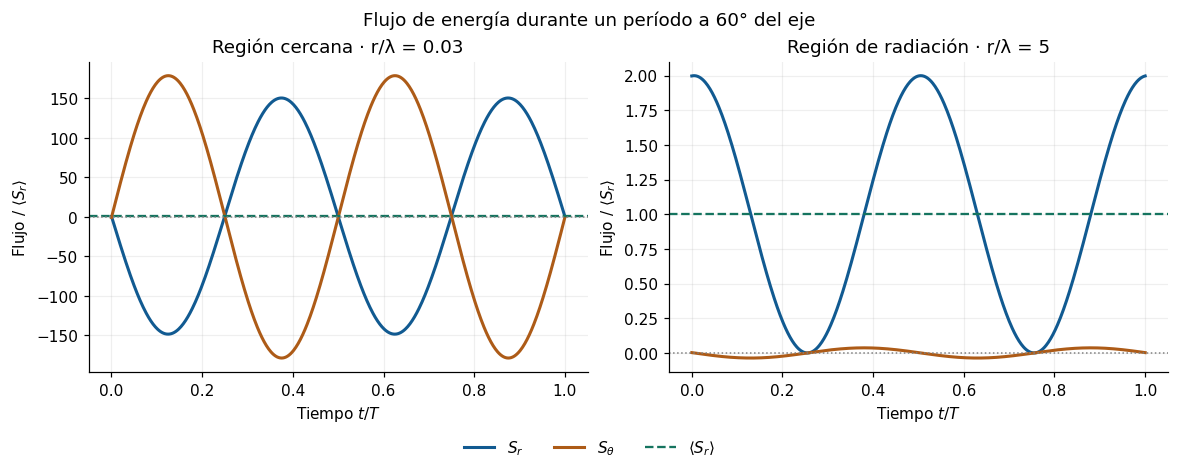

In [21]:
theta = np.deg2rad(60)
fases = np.linspace(0, 1, 601)
puntos = (REGIMENES[0], REGIMENES[-1])

fig, axes = plt.subplots(1, 2, figsize=(10.6, 4.2), layout="constrained")

print(f"{'Región':24} {'r (m)':>9} {'<S_r> (W/m²)':>16}"
      f" {'<S_θ> (W/m²)':>16} {'|E_r|/|E|':>12}")

medias = []

for ax, (nombre, q) in zip(axes, puntos):
    r = q * LAMBDA
    sr, stheta = poynting_instantaneo(r, theta, fases / F)
    sr_medio, stheta_medio = poynting_promedio(r, theta)

    er, etheta, _ = campos_esfericos(r, theta, FASE / F)
    fraccion_radial = abs(er) / np.hypot(er, etheta)
    medias.append(sr_medio)

    print(f"{nombre:24} {r:9.4f} {sr_medio:16.6e}"
          f" {stheta_medio:16.6e} {fraccion_radial:12.4f}")

    ax.plot(fases, sr / sr_medio, color=AZUL, lw=2, label=r"$S_r$")
    ax.plot(fases, stheta / sr_medio, color=NARANJA, lw=2, label=r"$S_\theta$")
    ax.axhline(1, color=VERDE, ls="--", label=r"$\langle S_r\rangle$")
    ax.axhline(0, color="gray", ls=":", lw=1)

    ax.set(
        title=f"{nombre} · r/λ = {q:g}",
        xlabel=r"Tiempo $t/T$",
        ylabel=r"Flujo / $\langle S_r\rangle$",
    )
    ax.grid(alpha=0.2)

print(f"\nFlujo medio cercano / lejano = {medias[0] / medias[1]:,.1f}")
print(f"La última columna se evalúa en t/T = {FASE:g}.")

handles, etiquetas = axes[0].get_legend_handles_labels()
fig.legend(
    handles, etiquetas, loc="outside lower center",
    ncols=3, frameon=False,
)
fig.suptitle("Flujo de energía durante un período a 60° del eje")
guardar_figura(fig, "05_flujo_periodo.png")
plt.show()

La comparación temporal muestra algo que se pierde al mirar solo el promedio.
Cerca del dipolo, $S_r$ cambia de signo y $S_\theta$ puede ser grande durante
parte del ciclo. Ese flujo de ida y vuelta es compatible con el intercambio
de energía con el campo cercano. Lejos del dipolo, la componente angular es
pequeña y el flujo radial se aproxima a la forma de un coseno al cuadrado.

En ambos puntos, el promedio apunta hacia afuera. Como los puntos tienen
el mismo ángulo, la diferencia de magnitud entre ellos sigue la dependencia
$1/r^2$.

## 5. Patrón angular de radiación

Un área de la esfera que abarca un ángulo sólido $\mathrm{d}\Omega$ es
$r^2\mathrm{d}\Omega$. Por eso, la potencia promedio por unidad de ángulo
sólido resulta

$$
\frac{\mathrm{d}\langle P\rangle}{\mathrm{d}\Omega}
=
r^2\langle S_r\rangle
=
\frac{\mu_0p_0^2\omega^4}{32\pi^2c}\sin^2\theta.
$$

El factor $\sin\theta$ aparece tanto en el campo eléctrico de radiación
como en el magnético. Al multiplicarlos para calcular el flujo se obtiene
$\sin^2\theta$. La gráfica polar es un corte del patrón alrededor del
eje del dipolo.

 θ (°)      d<P>/dΩ (W/sr)    Fracción del máximo
     0        0.000000e+00                  0.000
    30        5.171290e-01                  0.250
    60        1.551387e+00                  0.750
    90        2.068516e+00                  1.000
   180        3.102277e-32                  0.000
Imagen guardada en C:\Users\gusta\figuras\06_patron_angular.png


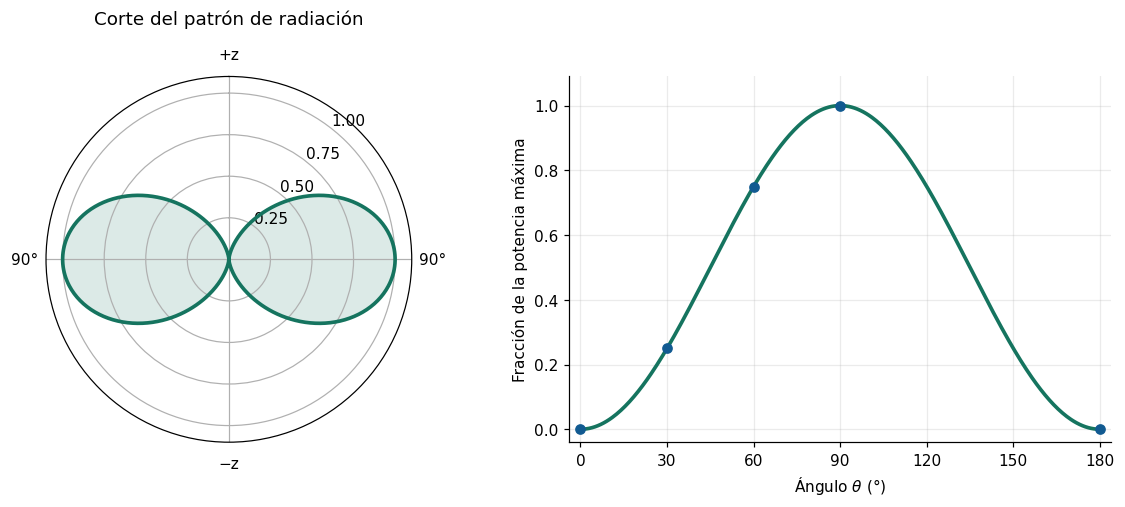

In [22]:
angulos = np.linspace(0, 2 * np.pi, 721)
theta = np.linspace(0, np.pi, 361)
maximo = potencia_por_angulo_solido(np.pi / 2)

fig = plt.figure(figsize=(10.6, 4.5), layout="constrained")
polar = fig.add_subplot(1, 2, 1, projection="polar")
perfil = fig.add_subplot(1, 2, 2)

patron = np.sin(angulos)**2
polar.set_theta_zero_location("N")
polar.set_theta_direction(-1)
polar.plot(angulos, patron, color=VERDE, lw=2.4)
polar.fill(angulos, patron, color=VERDE, alpha=0.15)
polar.set_thetagrids([0, 90, 180, 270], labels=["+z", "90°", "−z", "90°"])
polar.set_rgrids([0.25, 0.50, 0.75, 1.00], angle=38)
polar.set_ylim(0, 1.1)
polar.set_title("Corte del patrón de radiación", pad=15)

perfil.plot(
    np.rad2deg(theta),
    potencia_por_angulo_solido(theta) / maximo,
    color=VERDE, lw=2.4,
)

angulos_tabla = np.array([0, 30, 60, 90, 180])
valores = potencia_por_angulo_solido(np.deg2rad(angulos_tabla))
perfil.scatter(angulos_tabla, valores / maximo, color=AZUL, zorder=3)
perfil.set(
    xlabel=r"Ángulo $\theta$ (°)",
    ylabel="Fracción de la potencia máxima",
    xlim=(-4, 184),
    ylim=(-0.04, 1.09),
)
perfil.set_xticks([0, 30, 60, 90, 120, 150, 180])
perfil.grid(alpha=0.25)

print(f"{'θ (°)':>6} {'d<P>/dΩ (W/sr)':>19} {'Fracción del máximo':>22}")
for angulo, valor in zip(angulos_tabla, valores):
    print(f"{angulo:6d} {valor:19.6e} {valor / maximo:22.3f}")

guardar_figura(fig, "06_patron_angular.png")
plt.show()

A $30^\circ$ se obtiene el 25 % del máximo y a $60^\circ$ se obtiene
el 75 %. La emisión es mayor a $90^\circ$, en el plano perpendicular
al dipolo. Sobre el eje $z$, el término radiativo se anula porque
$\sin\theta=0$.

## 6. Comprobación de los resultados

Primero comparo el promedio analítico de Poynting con el promedio de
256 muestras tomadas a lo largo de un período. Después integro el flujo
medio en una esfera para cada una de las tres distancias.

Aunque el flujo por unidad de área disminuye al aumentar $r$, el área
de la esfera crece como $r^2$. Por eso la potencia total debe dar el
mismo valor en las tres esferas:

$$
\langle P\rangle=\frac{\mu_0p_0^2\omega^4}{12\pi c}.
$$

La integración numérica se usa para comprobar el resultado. Los campos
de todas las figuras vienen de las expresiones analíticas.

In [11]:
tiempos = np.arange(256) / (256 * F)
angulos = np.deg2rad([25, 60, 90])[:, None]
nodos, pesos = np.polynomial.legendre.leggauss(32)
theta_esfera = np.arccos(nodos)

omega = 2 * np.pi * F
potencia_teorica = MU0 * P0**2 * omega**4 / (12 * np.pi * C)

for nombre, q in REGIMENES:
    r = q * LAMBDA
    sr, stheta = poynting_instantaneo(r, angulos, tiempos)
    sr_analitico, _ = poynting_promedio(r, angulos[:, 0])

    error_radial = np.max(abs(np.mean(sr, axis=1) / sr_analitico - 1))
    residuo_angular = np.max(abs(np.mean(stheta, axis=1) / sr_analitico))

    sr_esfera, _ = poynting_promedio(r, theta_esfera)
    potencia_esfera = 2 * np.pi * r**2 * np.dot(pesos, sr_esfera)

    np.testing.assert_allclose(potencia_esfera, potencia_teorica, rtol=1e-12)
    assert error_radial < 1e-11 and residuo_angular < 1e-11

    print(
        f"{nombre:24} error radial = {error_radial:.2e} · "
        f"residuo angular = {residuo_angular:.2e} · "
        f"P = {potencia_esfera:.6e} W"
    )

print(f"\nPotencia teórica = {potencia_teorica:.6e} W")

r_lejano = 5 * LAMBDA
_, etheta, bphi = campos_esfericos(r_lejano, np.pi / 2, r_lejano / C)
print(f"Eθ/(cBφ) en el ecuador a r = 5λ: {etheta / (C * bphi):.6f}")

Región cercana           error radial = 2.11e-15 · residuo angular = 6.49e-15 · P = 1.732916e+01 W
Transición               error radial = 4.44e-16 · residuo angular = 7.68e-16 · P = 1.732916e+01 W
Región de radiación      error radial = 2.22e-16 · residuo angular = 2.14e-18 · P = 1.732916e+01 W

Potencia teórica = 1.732916e+01 W
Eθ/(cBφ) en el ecuador a r = 5λ: 0.998987


## 7. Explorar otras distancias e instantes

Los controles permiten cambiar el instante y elegir uno de los tres anillos.
Con «Distancia libre» también puedo mover el anillo a cualquier distancia
entre $0.012\lambda$ y $10\lambda$.

Una forma de explorar el flujo es elegir la región cercana y mover el tiempo
hasta ver que cambia de dirección. Después puedo pasar al promedio para
comparar el movimiento de energía durante el ciclo con el transporte neto.

**Referencia.** David J. Griffiths, *Introduction to Electrodynamics*,
cuarta edición, problema 10.34 y sección 11.1.4.

In [9]:
import ipywidgets as widgets
from IPython.display import display


def explorar(region, distancia, fase, flujo):
    if region == "libre":
        seleccion = ("Distancia seleccionada", distancia)
    else:
        seleccion = REGIMENES[int(region)]

    fig = figura_cortes(
        regimenes=(seleccion,),
        fase=fase,
        promedio=(flujo == "Promedio"),
    )
    display(fig)
    plt.close(fig)


opciones = [(nombre, str(i)) for i, (nombre, _) in enumerate(REGIMENES)]
opciones.append(("Distancia libre", "libre"))

controles = widgets.interactive(
    explorar,
    region=widgets.Dropdown(
        options=opciones, value="0", description="Región",
    ),
    distancia=widgets.FloatLogSlider(
        value=0.1, base=10, min=-1.92, max=1, step=0.02,
        description="r/λ libre", readout_format=".3f",
        continuous_update=False,
    ),
    fase=widgets.FloatSlider(
        value=FASE, min=0, max=1, step=0.025,
        description="t/T", continuous_update=False,
    ),
    flujo=widgets.ToggleButtons(
        options=["Instantáneo", "Promedio"], description="Flujo",
    ),
)

display(controles)

interactive(children=(Dropdown(description='Región', options=(('Región cercana', '0'), ('Transición', '1'), ('…

## Retrospectiva

Lo que entendí mejor con la gráfica fue que, cerca del dipolo, la
energía puede fluir hacia afuera durante una parte del ciclo y hacia
el dipolo durante otra. Eso se ve en la curva de $S_r$ del punto
cercano, que pasa por encima y por debajo de cero.

La componente radial del vector de Poynting es

$$
S_r = \frac{E_\theta B_\phi}{\mu_0}.
$$

Cerca del dipolo, los términos que dependen de $1/r^3$ y $1/r^2$
hacen que $E_\theta$ y $B_\phi$ puedan tener signos opuestos durante
parte del ciclo. Cuando eso pasa, $S_r<0$ y parte de la energía del
campo cercano fluye de vuelta hacia la fuente.

Ver la curva instantánea junto con la línea del promedio me ayudó
a entender que el flujo puede cambiar de sentido durante el ciclo.
El promedio $\langle S_r\rangle$ queda por encima de cero, así que
hay un transporte neto de energía hacia afuera.

In [16]:
from pathlib import Path

CARPETA_FIGURAS = Path("figuras")
CARPETA_FIGURAS.mkdir(exist_ok=True)

def guardar_figura(fig, nombre):
    ruta = CARPETA_FIGURAS / nombre
    fig.savefig(ruta, dpi=300, bbox_inches="tight", facecolor="white")
    print(f"Figura guardada en {ruta.resolve()}")